# Hand Gesture Control

In [2]:
import cv2
import mediapipe as mp
print(cv2.__version__, mp.__version__)
print(hasattr(mp, "solutions"))

5.0.0 1.2.3
False


In [3]:
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
print(hasattr(vision, "HandLandmarker"))

True


In [4]:
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1
)
detector = vision.HandLandmarker.create_from_options(options)
print("detector ready")

detector ready


In [7]:
cap = cv2.VideoCapture(0)
ok, frame = cap.read()
cap.release()
print("camera ok:", ok)

rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
result = detector.detect(image)
print("hands found:", len(result.hand_landmarks))

camera ok: True
hands found: 1


In [8]:
lm = result.hand_landmarks[0]
print("number of points:", len(lm))
print("wrist (point 0):", lm[0].x, lm[0].y)
print("index fingertip (point 8):", lm[8].x, lm[8].y)

number of points: 21
wrist (point 0): 0.3668033182621002 1.1786260604858398
index fingertip (point 8): 0.5152528285980225 0.6047310829162598


In [9]:
def get_features(landmarks):
    wrist_x, wrist_y = landmarks[0].x, landmarks[0].y
    coords = [(p.x - wrist_x, p.y - wrist_y) for p in landmarks]
    scale = max(max(abs(x), abs(y)) for x, y in coords)
    features = []
    for x, y in coords:
        features.append(x / scale)
        features.append(y / scale)
    return features

features = get_features(lm)
print(len(features))
print(features[:4])

42
[0.0, 0.0, 0.12277887503007612, -0.05120944637234779]


## Collecting the data: 4 gestures, 3 sessions

In [16]:
import time
import cv2
import mediapipe as mp
import pandas as pd
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1
)
detector = vision.HandLandmarker.create_from_options(options)

def get_features(landmarks):
    wrist_x, wrist_y = landmarks[0].x, landmarks[0].y
    coords = [(p.x - wrist_x, p.y - wrist_y) for p in landmarks]
    scale = max(max(abs(x), abs(y)) for x, y in coords)
    features = []
    for x, y in coords:
        features.append(x / scale)
        features.append(y / scale)
    return features

gestures = ["open_palm", "fist", "victory", "thumbs_up"]
columns = [c + str(i) for i in range(21) for c in ("x", "y")] + ["label", "session"]
print("ready")

ready


In [17]:
all_rows = []

def run_session(session, n=100, wait=5):
    cap = cv2.VideoCapture(0)
    for g in gestures:
        start = time.time()
        rows = []
        attempts = 0
        while len(rows) < n and attempts < 1000:
            attempts += 1
            ok, frame = cap.read()
            if not ok:
                continue
            h, w = frame.shape[:2]
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
            found = len(result.hand_landmarks) == 1
            ready = (time.time() - start) >= wait

            show = cv2.flip(frame, 1)
            if found:
                for p in result.hand_landmarks[0]:
                    cv2.circle(show, (int((1 - p.x) * w), int(p.y * h)), 4, (0, 255, 0), -1)
                if ready:
                    rows.append(get_features(result.hand_landmarks[0]) + [g, session])

            if ready:
                text = g + "  " + str(len(rows)) + "/" + str(n)
            else:
                text = "GET READY: " + g + " in " + str(int(wait - (time.time() - start)) + 1)
            cv2.putText(show, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
            cv2.imshow("Collecting", show)
            cv2.waitKey(50)

        all_rows.extend(rows)
        print("collected", len(rows), "for", g)

    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    pd.DataFrame(all_rows, columns=columns).to_csv("gestures.csv", index=False)
    print("saved. total rows:", len(all_rows))

run_session(1)

collected 100 for open_palm
collected 100 for fist
collected 100 for victory
collected 100 for thumbs_up
saved. total rows: 400


In [18]:
run_session(2)

collected 100 for open_palm
collected 100 for fist
collected 100 for victory
collected 100 for thumbs_up
saved. total rows: 800


In [19]:
run_session(3)

collected 100 for open_palm
collected 100 for fist
collected 100 for victory
collected 100 for thumbs_up
saved. total rows: 1200


## Recording thumbs_up again

In [25]:
data = pd.read_csv("gestures.csv")
all_rows = data[data["label"] != "thumbs_up"].values.tolist()
gestures = ["thumbs_up"]

def run_session(session, n=100, wait=5):
    cap = cv2.VideoCapture(0)
    for g in gestures:
        start = time.time()
        rows = []
        attempts = 0
        while len(rows) < n and attempts < 1000:
            attempts += 1
            ok, frame = cap.read()
            if not ok:
                continue
            h, w = frame.shape[:2]
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
            found = len(result.hand_landmarks) == 1
            ready = (time.time() - start) >= wait

            show = cv2.flip(frame, 1)
            if found:
                for p in result.hand_landmarks[0]:
                    cv2.circle(show, (int((1 - p.x) * w), int(p.y * h)), 4, (0, 255, 0), -1)
                if ready:
                    rows.append(get_features(result.hand_landmarks[0]) + [g, session])

            if ready:
                text = g + "  " + str(len(rows)) + "/" + str(n)
            else:
                text = "GET READY: " + g + " in " + str(int(wait - (time.time() - start)) + 1)
            cv2.putText(show, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
            cv2.imshow("Collecting", show)
            cv2.waitKey(50)

        all_rows.extend(rows)
        print("collected", len(rows), "for", g)

    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    pd.DataFrame(all_rows, columns=columns).to_csv("gestures.csv", index=False)
    print("saved. total rows:", len(all_rows))

print("rows kept (without thumbs_up):", len(all_rows))
run_session(1)

rows kept (without thumbs_up): 900
collected 100 for thumbs_up
saved. total rows: 1000


In [26]:
run_session(2)

collected 100 for thumbs_up
saved. total rows: 1100


In [27]:
run_session(3)

collected 100 for thumbs_up
saved. total rows: 1200


## Session 4: a new recording for the final test

In [29]:
gestures = ["open_palm", "fist", "victory", "thumbs_up"]
run_session(4)

collected 100 for open_palm
collected 100 for fist
collected 100 for victory
collected 100 for thumbs_up
saved. total rows: 1600


## Adding 3 new gestures: thumbs_down, ok, call_me

In [2]:
data = pd.read_csv("gestures.csv")
all_rows = data.values.tolist()
gestures = ["thumbs_down", "ok", "call_me"]

def run_session(session, n=100, wait=5):
    cap = cv2.VideoCapture(0)
    for g in gestures:
        start = time.time()
        rows = []
        attempts = 0
        while len(rows) < n and attempts < 1000:
            attempts += 1
            ok, frame = cap.read()
            if not ok:
                continue
            h, w = frame.shape[:2]
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            result = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
            found = len(result.hand_landmarks) == 1
            ready = (time.time() - start) >= wait

            show = cv2.flip(frame, 1)
            if found:
                for p in result.hand_landmarks[0]:
                    cv2.circle(show, (int((1 - p.x) * w), int(p.y * h)), 4, (0, 255, 0), -1)
                if ready:
                    rows.append(get_features(result.hand_landmarks[0]) + [g, session])

            if ready:
                text = g + "  " + str(len(rows)) + "/" + str(n)
            else:
                text = "GET READY: " + g + " in " + str(int(wait - (time.time() - start)) + 1)
            cv2.putText(show, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
            cv2.imshow("Collecting", show)
            cv2.waitKey(50)

        all_rows.extend(rows)
        print("collected", len(rows), "for", g)

    cap.release()
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    pd.DataFrame(all_rows, columns=columns).to_csv("gestures.csv", index=False)
    print("saved. total rows:", len(all_rows))

print("existing rows:", len(all_rows))
run_session(1)

existing rows: 1600
collected 100 for thumbs_down
collected 100 for ok
collected 100 for call_me
saved. total rows: 1900


In [3]:
run_session(2)

collected 100 for thumbs_down
collected 100 for ok
collected 100 for call_me
saved. total rows: 2200


In [4]:
run_session(3)

collected 100 for thumbs_down
collected 100 for ok
collected 100 for call_me
saved. total rows: 2500


In [5]:
run_session(4)

collected 100 for thumbs_down
collected 100 for ok
collected 100 for call_me
saved. total rows: 2800


## Explore the data

In [ ]:
data = pd.read_csv("gestures.csv")
feature_cols = [c for c in data.columns if c not in ["label", "session"]]

print("Shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())

Shape: (2800, 44)
Missing values: 0


In [ ]:
data.groupby(["session", "label"]).size().unstack()

label,call_me,fist,ok,open_palm,thumbs_down,thumbs_up,victory
session,,,,,,,
1,100,100,100,100,100,100,100
2,100,100,100,100,100,100,100
3,100,100,100,100,100,100,100
4,100,100,100,100,100,100,100


In [ ]:
print("smallest value:", data[feature_cols].min().min())
print("largest value:", data[feature_cols].max().max())

smallest value: -1.0
largest value: 1.0


## Random Forest: validate on session 2

              precision    recall  f1-score   support

     call_me       0.76      0.81      0.78       100
        fist       0.95      0.63      0.76       100
          ok       1.00      0.82      0.90       100
   open_palm       0.85      1.00      0.92       100
 thumbs_down       0.88      1.00      0.94       100
   thumbs_up       0.82      0.93      0.87       100
     victory       1.00      1.00      1.00       100

    accuracy                           0.88       700
   macro avg       0.89      0.88      0.88       700
weighted avg       0.89      0.88      0.88       700

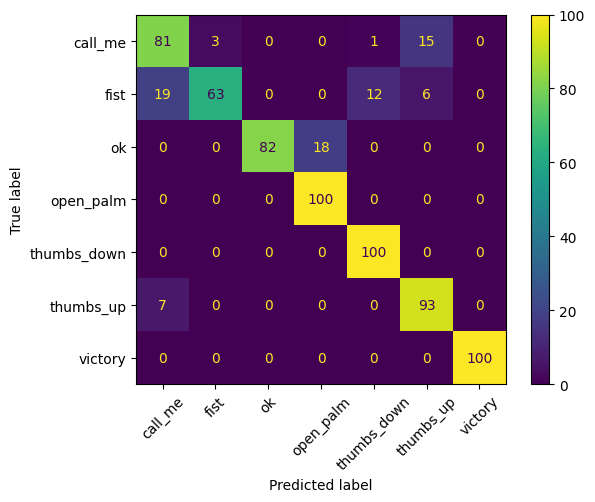

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay

data = pd.read_csv("gestures.csv")
feature_cols = [c for c in data.columns if c not in ["label", "session"]]
train = data[data["session"] == 1]
val = data[data["session"] == 2]

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(train[feature_cols], train["label"])
val_pred = rf.predict(val[feature_cols])

ConfusionMatrixDisplay.from_predictions(val["label"], val_pred, xticks_rotation=45)

print(classification_report(val["label"], val_pred))

## Final test on session 4

              precision    recall  f1-score   support

     call_me       0.88      1.00      0.93       100
        fist       0.96      0.98      0.97       100
          ok       1.00      1.00      1.00       100
   open_palm       1.00      1.00      1.00       100
 thumbs_down       0.98      1.00      0.99       100
   thumbs_up       1.00      0.81      0.90       100
     victory       0.99      1.00      1.00       100

    accuracy                           0.97       700
   macro avg       0.97      0.97      0.97       700
weighted avg       0.97      0.97      0.97       700



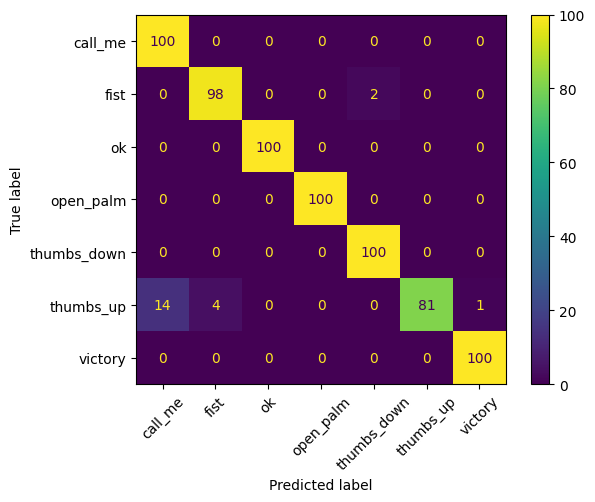

In [9]:
train_all = data[data["session"].isin([1, 2, 3])]
test4 = data[data["session"] == 4]

rf_final = RandomForestClassifier(n_estimators=100, random_state=42)
rf_final.fit(train_all[feature_cols], train_all["label"])
pred4 = rf_final.predict(test4[feature_cols])

print(classification_report(test4["label"], pred4))
ConfusionMatrixDisplay.from_predictions(test4["label"], pred4, xticks_rotation=45)